# 20 Tagesmonitor mit CUSUM

Teil 5: Anomalien und Monitoring

**Worum es geht**
- Frage: Läuft die Station schlechter als früher? Jede Station wird jeden Heiztag mit sich selbst verglichen.
- Gegenstück zum Netzvergleich (Notebook 19: Station gegen alle anderen, je Kernwinter). Die Idee stammt aus dem Normalverhaltensmodell (Notebook 18). Der Tagesmonitor ersetzt den Fensteralarm aus Notebook 13.
- Zwei Kanäle je Heiztag (Tagesmittel unter 15 °C): Abkühlung in kWh/m³ (etwa Spreizung × 1,16, Spreizung = Vorlauf minus Rücklauf) und Wassermenge.
- Im ersten Jahr (Lernjahr) lernt das Modell, welcher Wert bei welcher Außentemperatur normal ist. Danach summiert ein CUSUM die Abweichungen auf (CUSUM = Summe der Abweichungen, schlägt an, wenn sie zu groß wird).
- Geprüft wird: Hilft die Temperatur (Abschnitt 3)? Trifft der Alarm Begehungen öfter als Stationen ohne Begehung (Abschnitt 6)? Ändert die Begehung die Station messbar (Abschnitt 7)? Findet eine einfache Größe dieselben schlechten Stationen wie der Netzvergleich (Abschnitt 8)?

**Daten**
- liest: Stundenreihen und Zählerstände aus Notebook 00, Begehungstermine und Befundtexte, Anschlusswerte, Tagesmittel der Außentemperatur (DWD)
- schreibt: nichts
- vorher ausführen: Notebook 00

**Code**
- Logik in `src/tagesmonitor.py`, Einbindung in `src/stationsblatt.py`, Beschreibung in `docs/kennlinien-monitor.md`
- Tests in `tests/test_tagesmonitor.py`, `tests/test_stationsblatt.py`

**CUSUM kurz erklärt**
- z = (heute minus erwartet aus dem Lernjahr) / übliche Schwankung der Station
- Konto: jeden Tag + z − 0,5, nie unter 0, Alarm wenn das Konto über 5 steigt. Zwei Konten: über und unter der Erwartung.
- Ein einzelner Ausreißer verpufft, eine dauerhafte Verschiebung summiert sich (z = 1: Alarm nach etwa 11 Tagen, z = 2: nach 4 Tagen).
- Alarm mit Richtung: schlechter (Abkühlung sinkt oder Wasser steigt) oder besser. Ein neuer Alarm in dieselbe Richtung kommt erst, wenn das Konto zwischendurch bei 0 war.
- Grenze: Gelernt wird das Übliche, nicht das Gute. War die Station im Lernjahr schon kaputt, gilt kaputt als normal (68956351). Deshalb braucht es den Netzvergleich daneben.

**Was ins Ergebnis eingeht**
- Alarm „schlechter“ in der Heizperiode (Oktober bis April) und im Netz auffällig: Priorität hoch. Nur eins davon: mittel.
- Abkühlung bei 5 °C nur als Info in der Statuszeile, nicht im Score.

In [1]:
import os as _os
from pathlib import Path as _Path
#Arbeitsordner ist immer notebooks/, auch aus den Teil-Ordnern
_os.chdir(next(p for p in [_Path.cwd(), *_Path.cwd().parents] if (p / "src").is_dir()) / "notebooks")
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src import befundcodes as bc
from src import stationsblatt as bl
from src import tagesmonitor as tm

warnings.filterwarnings("ignore", category=UserWarning, module="openpyxl")
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)

BEISPIEL = 68956351

t0 = time.time()
e = bl.eingaben(ROOT)
erg = bl.rechne(e["serien"], e["termine"], e["anschlusswerte"], e["bhkw"],
                e["ohne_datum"])
r = erg["tagesmonitor"]
termine = erg["termine"]
print(f"{len(e['serien'])} Stundenreihen aus NB 00, gerechnet in "
      f"{time.time() - t0:.0f} s")

93 Stundenreihen aus NB 00, gerechnet in 16 s


## 1 Tageswerte und Ausschlüsse

- Der Tagesmonitor nutzt nur Zählerstände (Energie, Volumen) und das Tagesmittel der Außentemperatur. Stundenwerte nur für Nebensachen (Messstunden zählen, Prüfung „Zähler steht“).
- Warum: Der Tagesverbrauch aus Zählerständen ist exakt, Stundenwerte sind nur Momentaufnahmen (Prüfung D2 in Notebook 10). Zählerstände gibt es auch in der Tageswert-Phase. Der Tageswert glättet Spitzen.
- Was fehlt: Nachtdurchfluss, Takten, Tagesgang, Rücklauf und Vorlauf einzeln. Der Netzvergleich (Notebook 19) nutzt die Stundenwerte. Rücklauf und Nachtdurchfluss deckt der LSTM-Wächter (Notebook 28) ab.

**Tageswert**
- Zählerstand um Mitternacht am Anfang und Ende des Tages, Differenz = Verbrauch der 24 h (Zähler zählen fortlaufend wie ein Kilometerzähler).
- Toleranz ±2 h: Fehlt ein Stand um 0 Uhr, wird der nächste zwischen 22 und 2 Uhr genommen und auf 24 h hochgerechnet. In der Tageswert-Phase (bis Ende 2022, 1 Wert um 23 Uhr) reicht das für den vollen Tagesverbrauch.
- Abkühlung = Energie / Volumen (kWh/m³), Wassermenge = Volumen (im Modell als Logarithmus). Heiztag = Tagesmittel unter 15 °C. Regeln aus Notebook 10 übernommen.

**Ausschlüsse**
- Kein Tag wird gelöscht, der Grund steht dran. Ein Tag kann mehrere Gründe haben.
- Gründe: kein Zählerstand ±2 h um Mitternacht, Rücksprung (Zählerstand sinkt), Zähler steht (Volumen 0 trotz Durchfluss ab 20 l/h oder Energie 0 trotz Leistung ab 1 kW) und der Folgetag danach, unter 5 kWh am Tag, unplausibel (über 70 kWh/m³, etwa 60 K Spreizung), kein Tagesmittel der Temperatur (unter 20 Wetterstunden), unter 12 Messstunden.

In [2]:
tage = r["tage"]
print(f"{len(tage)} Stationstage, davon {int(tage['nutzbar'].sum())} nutzbar, "
      f"{len(r['modelltage'])} nutzbare Heiztage")
r["ausschluss"]

85983 Stationstage, davon 78350 nutzbar, 55746 nutzbare Heiztage


,grund,tage,stationen,ignoriert
0,kein_zaehlerstand,239,93,False
1,ruecksprung,3,1,False
2,zaehler_steht,24,2,False
3,nach_stillstand,24,2,False
4,wenig_energie,7317,52,False
5,unplausibel,19,8,False
6,wenig_stunden,16045,69,True
7,ohne_wetter,42,42,False


- 85.983 Stationstage (Tage mit mindestens einer Durchflussmessung), davon 78.350 nutzbar (91 %), davon 55.746 nutzbare Heiztage. Nur mit diesen rechnet der Tagesmonitor.
- Größte Gründe: wenig Energie 7.317 Tage (Sommer, Leerstand), kein Zählerstand 239 Tage (fast alle Stationen, meist erster oder letzter Tag der Reihe).
- Wenige Messstunden (16.045 Tage) wird ignoriert. Die Tageswert-Phase hat nur 1 Wert pro Tag, der Zählerstand reicht. Sonst fehlten die frühen Jahre, in denen oft das Lernjahr liegt.

## 2 Lernjahr je Station

- Start = erster nutzbarer Heiztag, Dauer 365 Kalendertage.
- Liegt eine Begehung im Lernjahr, endet es 14 Tage vor der ersten Begehung. So beschreibt es den Zustand vor dem Eingriff.
- Überwacht wird nur mit mindestens 60 Heiztagen, mindestens 8 K Temperaturspanne und Tagen nach dem Lernjahr.
- Gelernt wird: Abkühlung als robuste Gerade (Theil-Sen) über der Tagesmitteltemperatur. Wassermenge als Median je 2-K-Temperaturklasse (mindestens 8 Tage je Klasse), weil sie nicht linear ist. Dazu je Station die übliche Schwankung und ein Faktor für träge Stationen.

In [3]:
ref = r["referenz"]
display(ref["status"].value_counts().rename("Stationen").to_frame())
display(ref.groupby("ende_grund")[["ref_tage", "ref_spanne_k",
                                   "ueberwachte_tage"]].median().round(1))

,Stationen
status,
ok,89
keine Tage nach der Referenz,4


,ref_tage,ref_spanne_k,ueberwachte_tage
ende_grund,,,
ein Jahr,230.5,20.0,504.5
vor Begehung,209.0,21.0,240.0


- 89 Stationen überwacht, 4 nicht (keine Tage nach dem Lernjahr):
  - 80912191, 81019433, 81050517: Daten erst ab 09 bis 12/2024, das Lernjahr würde nach Datenende (07/2025) enden
  - 80912165: Lernjahr endet vor der Begehung, danach keine nutzbaren Heiztage
- Ende nach einem Jahr: 72 Stationen (Median 230 Lerntage, 20 K Spanne, 504 überwachte Heiztage). Ende vor Begehung: 21 Stationen (Median 209 Lerntage, 21 K, nur 240 überwachte Heiztage).
- Zwei Gruppen nach Datenbeginn: 43 Stationen ab 11/2021 mit Lernjahr 11/2021 bis 11/2022 und langer Überwachung. 43 Stationen erst ab 09 bis 11/2023, Lernjahr im Winter 2023/24, oft durch die Begehung im Herbst 2024 gekürzt. Bei ihnen beginnt die Überwachung praktisch erst mit der Begehung.
- 68956351: Lernjahr 02.11.2021 bis 02.11.2022 (234 Heiztage, 20 K), 645 überwachte Heiztage. Das Ventil war im Lernjahr schon offen.

## 3 Hilft die Temperatur überhaupt?

- Vergleich: gelernte Kurve (Wert bei dieser Außentemperatur) gegen eine Konstante (Median des Lernjahrs).
- Geprüft auf ungesehenen Tagen: die ersten 120 Heiztage nach dem Lernjahr, bis 7 Tage vor der nächsten Begehung, mindestens 20 Tage.
- Skill = 1 − Fehler(Kurve) / Fehler(Median), Fehler = mittlere absolute Abweichung. 1 = perfekt, 0 = Temperatur bringt nichts, negativ = Kurve schlechter als der Median.

,count,mean,std,min,25%,50%,75%,max
kanal,,,,,,,,
kwh_pro_m3,67.0,-0.01,0.40,-2.22,-0.15,0.01,0.23,0.54
log_volumen,67.0,0.25,0.24,-0.49,0.13,0.28,0.39,0.70


,Anteil Skill > 0
kanal,
kwh_pro_m3,0.54
log_volumen,0.84


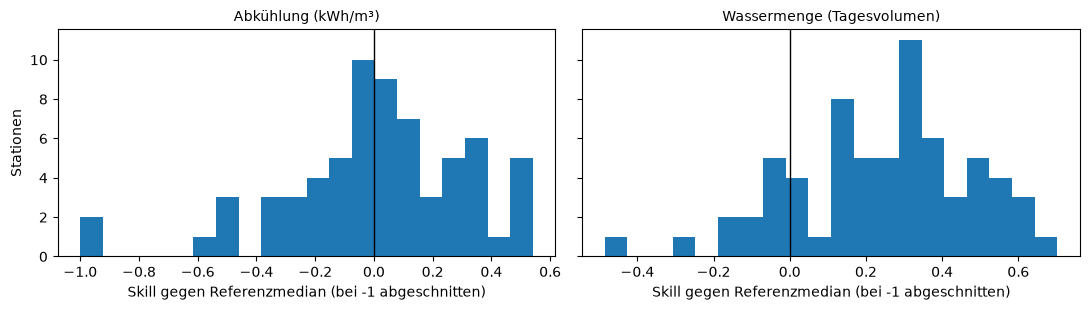

In [4]:
g = tm.guete(r["modelltage"], ref, r["modelle"], termine)
display(g.groupby("kanal")["skill"].describe().round(2))
display(g.groupby("kanal")["skill"].apply(lambda s: (s > 0).mean())
        .rename("Anteil Skill > 0").round(2).to_frame())
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2), sharey=True)
for a, (kanal, titel) in zip(ax, tm.KANAELE.items()):
    s = g.loc[g["kanal"] == kanal, "skill"].clip(-1, 1)
    a.hist(s, bins=20, color="C0")
    a.axvline(0, color="k", lw=1)
    a.set_title(titel, fontsize=10)
    a.set_xlabel("Skill gegen Referenzmedian (bei -1 abgeschnitten)")
ax[0].set_ylabel("Stationen")
plt.tight_layout()
plt.show()

- 67 Stationen im Test (bei Lernjahr kurz vor der Begehung gibt es zu wenige Prüftage).
- Wassermenge: Skill im Median 0,28, bei 84 % positiv. Die Temperatur hilft klar (kalt = mehr Wasser).
- Abkühlung: Skill im Median 0,01, nur 54 % positiv, einzelne Stationen bis −2,2. Im Winter hängt kWh/m³ kaum von der Außentemperatur ab, die Kurve ist fast eine Konstante. Für den CUSUM reicht das als stabile Erwartung, das Wetter wird bei der Abkühlung aber kaum herausgerechnet.

**Kälteeinbrüche und Fehlalarme**
- Beispiel 09. bis 12.12.2022: Tagesmittel 3,4 → −3,7 °C, Netz-Vorlauf gleich (73,7 → 73,8 °C). Die Häuser brauchen mehr Wärme, Ventile öffnen, mehr Wasser fließt, der Rücklauf steigt, kWh/m³ sinkt. Das ist physikalisch normal und kein Hausfehler.
- Der Tagesmonitor meldet trotzdem „schlechter“: Die Abkühlungskurve erwartet den Abfall nicht. Bei der Wassermenge bleibt die Kurve beim kältesten gelernten Wert stehen. Und Gebäude reagieren verzögert auf das Tagesmittel desselben Tages.
- Höhere Schwelle h hilft nur teilweise: Mit h = 5 können schon 4 bis 6 Tage Kälte alarmieren. h = 8 gibt etwa 1/3 weniger Alarme, meldet echte Änderungen aber später.
- Im Modell (Notebook 24): Viele gleichzeitige Alarme (±3 Tage, mehr als zufällig) gelten als Netzereignis. Unser Lauf: 1 Welle 09. bis 12.12.2022 bei 12 von 40 Stationen. An Tagen mit mindestens 5 K Abkühlung binnen einer Woche gibt es gut doppelt so viele Verschlechterungen (8,3 % gegen 3,8 % der Stationen).

**Mögliche Lösungen**
- Temperatur der letzten 2 bis 3 Tage mitteln oder 1 Tag verzögern (Gebäudeträgheit).
- Kurve über die kälteste gelernte Temperatur hinaus fortschreiben.
- Der Vorlauf hilft nur bei Netzänderungen, z. B. Nov. 2024: 70,2 → 72,4 °C bei allen Stationen, zusammen mit Kälte und 12 Begehungen nicht trennbar.
- Der LSTM-Wächter (Notebook 28) lernt die Verzögerung aus der Vorgeschichte der letzten Woche.

## 4 Beispiel 68956351

- Station mit dem jahrelang offenen Ventil, repariert am 09.09.2024.
- Im Stationsblatt zeigt die 3. Zeile die CUSUM-Konten: grau Lernjahr, rot Abkühlung, blau Wassermenge, ▼ schlechter, △ besser, rote Linie Reparatur.
- `richtung` in der Alarmtabelle: 1 = Konto nach oben (Abkühlung besser, Wassermenge schlechter), −1 umgekehrt.

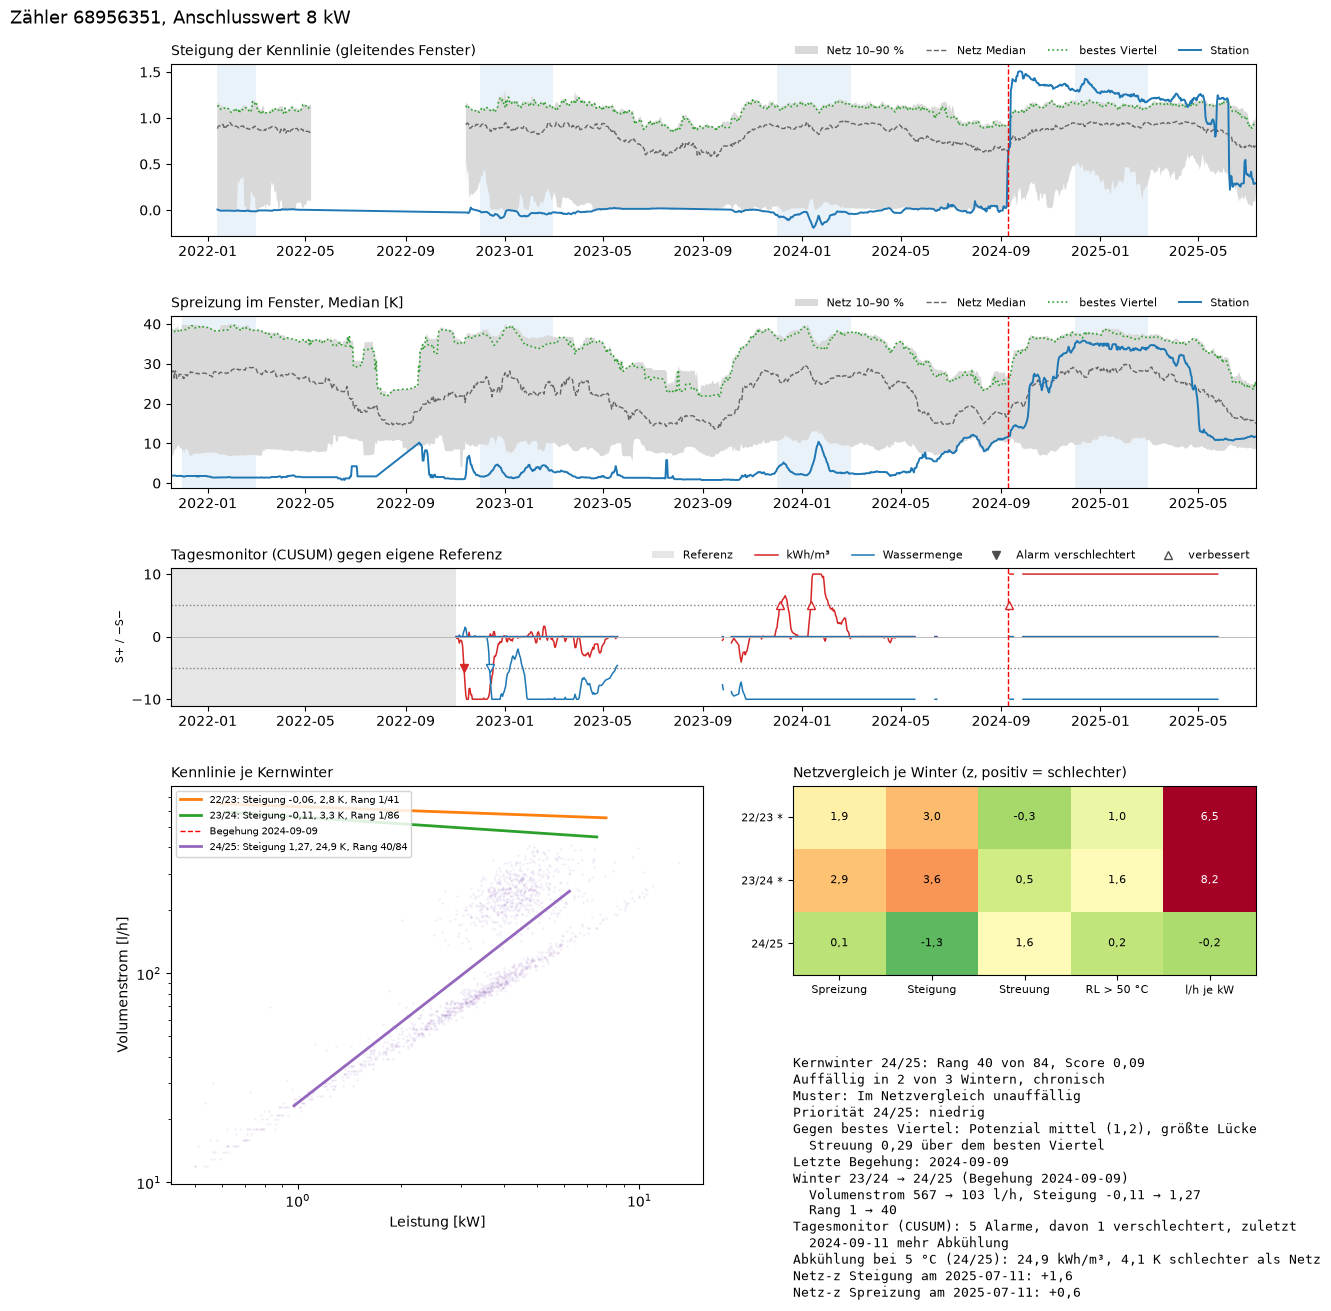

,meter,kanal,datum,richtung,beginn
133,68956351,kwh_pro_m3,2022-11-12,-1,2022-11-03
134,68956351,kwh_pro_m3,2023-12-05,1,2023-11-29
135,68956351,kwh_pro_m3,2024-01-12,1,2024-01-08
136,68956351,kwh_pro_m3,2024-09-11,1,2024-09-11
137,68956351,log_volumen,2022-12-14,-1,2022-12-09


In [5]:
fig = bl.zeichne_stationsblatt(BEISPIEL, erg)
plt.show()
display(r["alarme"][r["alarme"]["meter"] == BEISPIEL])

**Die 5 Alarme**
- 12.11.2022 Abkühlung schlechter (Beginn 03.11., direkt nach dem Lernjahr). Fällt mit dem Ende der Tageswert-Phase zusammen, Ursache unsicher.
- 14.12.2022 Wassermenge besser (Beginn 09.12. = Kälteeinbruch). Bei Kälte wurde mehr Wasser erwartet, das offene Ventil lieferte schon fast das Maximum. Kein echter Erfolg.
- 05.12.2023 und 12.01.2024 Abkühlung besser. Der Winter 23/24 war etwas besser als das Lernjahr, das Ventil aber noch offen (Netz-Rang 1).
- 11.09.2024 Abkühlung besser, 2 Tage nach der Reparatur (etwa 5 → 25 kWh/m³). Das ist der echte Erfolg.

**Was daraus folgt**
- Alarm heißt „anders als im Lernjahr“, nicht „kaputt“ oder „repariert“: 3 von 4 „besser“-Alarmen kamen bei noch offenem Ventil.
- Der Fehler selbst wurde nie gemeldet, weil das Lernjahr ihn schon enthielt. Nur der Netzvergleich zeigt ihn (Rang 1 in 22/23 und 23/24).
- Die Reparatur meldet nur die Abkühlung. Das Wasser-Konto hängt seit Dezember 2022 am Deckel (−10), ein neuer Alarm kommt erst nach Konto 0.
- Priorität: 22/23 hoch (auffällig und Alarm schlechter), 23/24 mittel (nur „besser“-Alarme), 24/25 niedrig.

## 5 Alarmlast

- Wie viele Alarme erzeugt der Tagesmonitor? Das ist die Arbeit, wenn man jeden Alarm prüft.
- Gezählt je Station und je 100 überwachte Heiztage, sonst hätten lang überwachte Stationen automatisch mehr.

In [6]:
al = r["alarme"]
ok = ref[ref["status"] == "ok"]
je_station = al.groupby("meter").size().reindex(ok.index, fill_value=0)
rate = 100 * je_station / ok["ueberwachte_tage"]
print(f"{len(al)} Alarme bei {al['meter'].nunique()} von {len(ok)} "
      f"überwachten Stationen")
print(f"je 100 überwachte Heiztage: Median {rate.median():.1f}, "
      f"oberes Quartil {rate.quantile(0.75):.1f}")
display(al.groupby(["kanal", "richtung"]).size().rename("Alarme").to_frame())

491 Alarme bei 84 von 89 überwachten Stationen
je 100 überwachte Heiztage: Median 1.2, oberes Quartil 1.7


Alarme
kanal       richtung        
kwh_pro_m3  -1           152
             1            96
log_volumen -1           148
             1            95

- 491 Alarme bei 84 von 89 Stationen, nur 5 ohne Alarm. Je Station Median 4 (mittlere Hälfte 2 bis 8, höchstens 20), 17 Stationen mit 10 oder mehr.
- Median 1,2 je 100 Heiztage (oberes Viertel 1,7), also gut 2 Alarme je Heizperiode und Station.
- Schlechter 247 (Abkühlung sinkt 152, Wasser steigt 95), besser 244 (Abkühlung steigt 96, Wasser sinkt 148).
- Je Heizperiode: 22/23 127, 23/24 161, 24/25 184 (zweite Stationsgruppe ab Herbst 2023, Begehungen Herbst 2024), 25/26 19.
- Fast jede Station alarmiert regelmäßig. Ein Alarm allein ist kein Grund für eine Begehung. Priorität hoch gibt es nur zusammen mit Netzauffälligkeit (24/25: 8 Stationen).
- Schwelle h (Notebook 21): h = 5 gibt 491 Alarme (Treffertest p 0,001), h = 8 gibt 335 (p 0,023), h = 10 gibt 282 (p 0,093). Höheres h heißt weniger Arbeit, aber schwächerer Bezug zu den Begehungen.

## 6 Treffertest gegen den Fenstermonitor aus Notebook 13

- Frage: Reagiert der Tagesmonitor auf Begehungen, und besser als der Fenstermonitor (Notebook 13, in der Ausgabe noch „NB 14“)?
- Fälle: datierte Begehungen. Mechanisch = der Freitext nennt Schmutzfänger, Ventil, Pumpe, Zirkulation oder Volumenstrom (Auto-Kodierung).
- Treffer = Alarm (egal welche Richtung) 7 Tage vor bis 60 Tage nach dem Termin. Kontrollquote = Anteil der Stationen ohne Begehung mit Alarm im selben Zeitraum. Das rechnet Herbst, Heizbeginn und Wetter heraus.
- Hebel = Trefferquote / Kontrollquote (1 = Zufall), p = Binomialtest einseitig.

In [7]:
faelle = tm.faelle(bc.kodiere_begehungen())
beob = tm.beobachtete_tage(r["verlauf"])
print(f"{len(faelle)} datierte Begehungsfälle, davon "
      f"{int(faelle['mechanisch'].sum())} mechanisch")

t_tm = tm.treffertest(faelle, r["alarme"], beob, termine)
a14 = erg["monitor"]["alarme"].rename(columns={"kennzahl": "kanal"})
t_14 = tm.treffertest(faelle, a14, beob, termine, pruefungen={
    "NB 14 Steigung": ["steigung"],
    "NB 14 Residuum": ["residuum_median"],
    "NB 14 einer der beiden": ["steigung", "residuum_median"]})
treffer = pd.concat([t_tm, t_14], ignore_index=True)
display(tm.bilanz(treffer, ["pruefung"]).round(3))
display(tm.bilanz(treffer, ["pruefung", "mechanisch"]).round(3))

58 datierte Begehungsfälle, davon 19 mechanisch


,pruefung,Faelle,Treffer,Quote,Kontrollquote,Hebel,p (einseitig)
0,Abkühlung,43,22,0.512,0.274,1.866,0.001
1,Wassermenge,43,22,0.512,0.359,1.427,0.028
2,einer der beiden,43,29,0.674,0.511,1.320,0.022
3,NB 14 Steigung,43,27,0.628,0.638,0.984,0.621
4,NB 14 Residuum,43,21,0.488,0.460,1.061,0.413
5,NB 14 einer der beiden,43,31,0.721,0.740,0.974,0.687


,pruefung,mechanisch,Faelle,Treffer,Quote,Kontrollquote,Hebel,p (einseitig)
0,Abkühlung,True,14,5,0.357,0.269,1.329,0.316
1,Wassermenge,True,14,9,0.643,0.376,1.708,0.039
2,einer der beiden,True,14,10,0.714,0.522,1.369,0.119
3,Abkühlung,False,29,17,0.586,0.277,2.118,0.000
4,Wassermenge,False,29,13,0.448,0.350,1.280,0.180
5,einer der beiden,False,29,19,0.655,0.505,1.296,0.076
6,NB 14 Steigung,True,14,10,0.714,0.672,1.063,0.493
7,NB 14 Residuum,True,14,9,0.643,0.494,1.302,0.198
8,NB 14 einer der beiden,True,14,11,0.786,0.779,1.009,0.624
9,NB 14 Steigung,False,29,17,0.586,0.621,0.943,0.723


- 58 datierte Begehungen (19 mechanisch), im Test 43 (mindestens 5 überwachte Tage im Fenster, mindestens 5 Kontrollstationen).
- Abkühlung: 22 von 43 (51 % gegen 27 %), Hebel 1,87, p = 0,001.
- Wassermenge: 22 von 43 (51 % gegen 36 %), Hebel 1,43, p = 0,028. Einer der beiden: Hebel 1,32, p = 0,022.
- Fenstermonitor: Hebel etwa 1 (0,98 und 1,00). Er schlägt auch ohne Begehung ständig an (Kontrolle 49 bis 75 %). Deshalb wurde er im Endmodell durch den Tagesmonitor ersetzt.

**Nach Art des Eingriffs**
- Abkühlung trifft vor allem nicht mechanische Eingriffe: 17 von 29, Hebel 2,1, p < 0,001 (mechanisch 5 von 14, nicht signifikant).
- Wassermenge trifft vor allem mechanische: 9 von 14, Hebel 1,7, p = 0,039. Das passt dazu, dass Hardware (Ventil, Schmutzfänger) den Durchfluss ändert und Einstellungen eher die Abkühlung. Mit den Handbefunden (frühere Fassung, archiviert) zeigte sich das gleiche Muster.

**Vorsicht**
- Gezählt werden Alarme beider Richtungen. Der Treffer kommt fast nur von „besser“ nach der Begehung (Richtungstest in Notebook 21). Der Monitor sieht also die Veränderung durch den Eingriff, er warnt nicht vorher.
- Das Fenster ist 67 Tage lang. Ein Treffer passt zeitlich, ist aber kein Beweis.
- Ein früherer Lauf ergab 23 von 43, Hebel 2,0.

## 7 Wirkung der Begehung: Differenz-in-Differenzen

- Residuum = gemessen minus erwartet aus dem Lernjahr. Das Wetter ist damit schon herausgerechnet.
- Delta begangen = Median Residuum der ersten 30 Heiztage nach dem Termin minus der letzten 30 Heiztage davor (7 Tage Abstand, höchstens 1 Jahr, mindestens 10 Tage je Seite).
- Delta Kontrolle = dieselbe Rechnung zum selben Datum bei Stationen ohne Begehung (Median). DiD (Differenz-in-Differenzen) = Delta begangen minus Delta Kontrolle.
- Erwartete Verbesserung: Abkühlung steigt, Wasser sinkt. Test: Wilcoxon (weichen die DiD systematisch von 0 ab?).

In [8]:
w = tm.wirkung(r["verlauf"], faelle, termine)
display(tm.wirkung_bilanz(w).round(3))
display(tm.wirkung_bilanz(w, ["kanal", "mechanisch"]).round(3))

,kanal,Faelle,Median Δ begangen,Median Δ Kontrolle,Median DiD,Anteil in erwarteter Richtung,p (Wilcoxon),Einheit
0,kwh_pro_m3,24,2.315,-0.553,2.248,0.625,0.046,kWh/m³
1,log_volumen,24,-0.195,12.328,-7.984,0.708,0.029,%


,kanal,mechanisch,Faelle,Median Δ begangen,Median Δ Kontrolle,Median DiD,Anteil in erwarteter Richtung,p (Wilcoxon),Einheit
0,kwh_pro_m3,True,7,3.794,-1.032,4.826,0.714,0.078,kWh/m³
1,log_volumen,True,7,-0.843,12.328,-13.905,0.857,0.031,%
2,kwh_pro_m3,False,17,1.025,-0.409,0.928,0.588,0.378,kWh/m³
3,log_volumen,False,17,0.623,4.442,-6.739,0.647,0.329,%


- 24 Fälle je Kanal. Es sind nur 24, weil der Verlauf erst nach dem Lernjahr beginnt: Endet das Lernjahr 14 Tage vor der Begehung, fehlen 10 Tage davor.
- Abkühlung: DiD +2,2 kWh/m³ (begangen +2,3, Kontrolle −0,6), 63 % in erwarteter Richtung, p = 0,046.
- Wasser: DiD −8,0 % (begangen −0,2 %, Kontrolle +12,3 %), 71 % in erwarteter Richtung, p = 0,029. Die Kontrolle steigt um 12 %, weil die Jahreszeit (Herbst zu Winter) von der Temperaturkurve nicht ganz abgefangen wird. Ohne Kontrolle wäre keine Wirkung sichtbar.
- Mechanisch (7 Fälle): Abkühlung +4,8 (p 0,078), Wasser −13,9 % (p 0,031). Nicht mechanisch (17): +0,9 und −6,7 %, nicht signifikant.
- Anders als der Wintervergleich in Notebook 19 (Abschnitt 6, ganze Kernwinter, keine Wirkung nachweisbar) ist die Wirkung hier knapp nachweisbar: 30 Tage eng um den Termin, Tageswerte, wetterbereinigt.

### 7.1 DiD gegen Wintervergleich

- Passen DiD und die Winteränderung aus Notebook 19 (Abschnitt 5) zusammen? Spearman über dieselben Begehungen.

In [9]:
wv = erg["vergleich"]
wv = wv[wv["status"] == "ok"][["meter", "datum", "d_steigung",
                               "flow_verhaeltnis"]].copy()
wv["datum"] = pd.to_datetime(wv["datum"]).dt.normalize()
zeilen = []
for kanal in tm.KANAELE:
    m = w[w["kanal"] == kanal].merge(wv, on=["meter", "datum"])
    for spalte in ("d_steigung", "flow_verhaeltnis"):
        rho, p = stats.spearmanr(m["did"], m[spalte])
        zeilen.append({"kanal": kanal, "Wintervergleich": spalte,
                       "Begehungen": len(m), "Spearman": rho, "p": p})
pd.DataFrame(zeilen).round(3)

,kanal,Wintervergleich,Begehungen,Spearman,p
0,kwh_pro_m3,d_steigung,23,0.443,0.034
1,kwh_pro_m3,flow_verhaeltnis,23,-0.383,0.072
2,log_volumen,d_steigung,23,-0.637,0.001
3,log_volumen,flow_verhaeltnis,23,0.410,0.052


- 23 Begehungen. Abkühlungs-DiD gegen Steigung +0,44 (p 0,034), gegen Wasser-Verhältnis −0,38 (p 0,072).
- Wasser-DiD gegen Steigung −0,64 (p 0,001), gegen Wasser-Verhältnis +0,41 (p 0,052).
- Mehr Abkühlung und weniger Wasser (DiD) gehen mit steilerer Kennlinie und weniger Wasser im Winter danach einher. Beide Maße sind sich einig, welche Begehungen gewirkt haben.
- Sie sind nicht unabhängig (dieselben Zähler), nutzen aber andere Zeiträume (30 Heiztage gegen Kernwinter) und Größen.

## 8 Gegenprobe: Abkühlung bei 5 °C gegen den Netzscore

- Je Station und Kernwinter aus den Tageswerten: robuste Gerade (Theil-Sen) kWh/m³ über der Tagesmitteltemperatur, mindestens 30 Heiztage und 5 K Spanne.
- Den Wert bei 5 °C ablesen. So werden alle Stationen bei derselben Temperatur verglichen.
- Abstand = (Netzmedian minus Station) / 1,15, also in K Spreizung, positiv = schlechter. BHKW nicht im Median.
- Grafik: x = Abstand bei 5 °C, y = Netzscore aus Notebook 19 (in der Achse noch „NB 20“). Rechts oben = nach beiden Maßen schlecht.

,Stationen,mit_Netzwert,Netzmedian
winter,,,
21/22,44,43,28.3
22/23,42,42,25.5
23/24,87,87,29.5
24/25,85,84,29.7
25/26,4,0,NaN


,winter,Stationen,Spearman,p,auffällig unter den 10 schlechtesten bei 5 °C
0,22/23,41,0.880,0.0,0.6
1,23/24,86,0.873,0.0,0.8
2,24/25,84,0.883,0.0,0.9


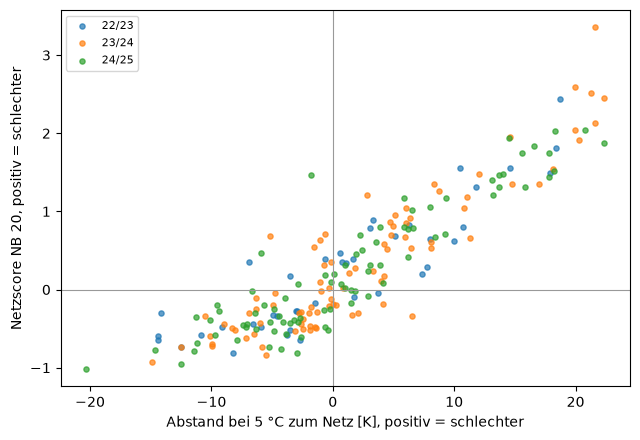

In [10]:
norm = r["norm"]
display(norm.groupby("winter").agg(Stationen=("meter", "size"),
                                   mit_Netzwert=("abstand_k", "count"),
                                   Netzmedian=("netz_median", "first"))
        .round(1))
mk = erg["markiert"][["meter", "winter", "score", "rang", "auffaellig"]]
x = norm.merge(mk, on=["meter", "winter"], suffixes=("_5c", "_netz"))
x = x.dropna(subset=["abstand_k", "score"])
zeilen = []
for winter, d in x.groupby("winter"):
    rho, p = stats.spearmanr(d["abstand_k"], d["score"])
    oben = d.nsmallest(10, "rang_5c")["auffaellig"].mean()
    zeilen.append({"winter": winter, "Stationen": len(d), "Spearman": rho,
                   "p": p, "auffällig unter den 10 schlechtesten bei 5 °C": oben})
display(pd.DataFrame(zeilen).round(3))

fig, ax = plt.subplots(figsize=(6.5, 4.5))
for winter, d in x.groupby("winter"):
    ax.scatter(d["abstand_k"], d["score"], s=14, label=winter, alpha=0.7)
ax.axhline(0, color="0.6", lw=0.8)
ax.axvline(0, color="0.6", lw=0.8)
ax.set_xlabel("Abstand bei 5 °C zum Netz [K], positiv = schlechter")
ax.set_ylabel("Netzscore NB 20, positiv = schlechter")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [11]:
for m in (80956410, 68956372, BEISPIEL):
    n = norm[norm["meter"] == m][["winter", "norm_kwh_m3", "abstand_k", "rang",
                                  "n_stationen"]]
    s = mk[mk["meter"] == m][["winter", "score", "rang", "auffaellig"]]
    print(f"Zähler {m}")
    display(n.merge(s, on="winter", how="outer", suffixes=("_5c", "_netz"))
            .round(2))

Zähler 80956410


,winter,norm_kwh_m3,abstand_k,rang_5c,n_stationen,score,rang_netz,auffaellig
0,23/24,27.72,1.57,40.0,87,-0.32,63.0,False
1,24/25,9.18,17.80,6.0,84,1.74,7.0,True


Zähler 68956372


,winter,norm_kwh_m3,abstand_k,rang_5c,n_stationen,score,rang_netz,auffaellig
0,21/22,29.81,-1.28,25.0,43,NaN,NaN,NaN
1,22/23,28.64,-2.74,24.0,42,-0.64,38.0,False
2,23/24,3.84,22.33,1.0,87,2.45,4.0,True
3,24/25,22.49,6.23,22.0,84,0.41,32.0,False
4,25/26,17.92,NaN,NaN,4,NaN,NaN,False


Zähler 68956351


,winter,norm_kwh_m3,abstand_k,rang_5c,n_stationen,score,rang_netz,auffaellig
0,21/22,4.54,20.70,2.0,43,NaN,NaN,NaN
1,22/23,3.93,18.75,1.0,42,2.44,1.0,True
2,23/24,4.65,21.63,3.0,87,3.36,1.0,True
3,24/25,24.94,4.10,26.0,84,0.09,40.0,False


- Stationen: 21/22 44, 22/23 42, 23/24 87, 24/25 85, 25/26 4 (kein Netzwert). Netzmedian 25,5 bis 29,7 kWh/m³. Anders als der Netzvergleich klappt das auch in 21/22.
- Spearman mit dem Netzscore: 0,88 (22/23), 0,87 (23/24), 0,88 (24/25). Von den 10 Schlechtesten bei 5 °C sind im Netzvergleich 6 / 8 / 9 auffällig.
- Teilweise eingebaut, weil kWh/m³ etwa der Spreizung entspricht und die auch im Netzscore steckt. Datenbasis (Zählerstände je Tag statt Momentaufnahmen je Stunde) und Methode (1 Gerade statt Kennlinie mit 5 Kennzahlen) sind aber unabhängig. Der Netzvergleich ist also kein Zufallsprodukt seiner Kennzahlauswahl.

**Einzelfälle**
- 80956410: 23/24 unauffällig (5 °C Rang 40, Netz Rang 63), 24/25 schlecht (+17,8 K, Rang 6; Netz Rang 7, auffällig). Beide Maße sehen die Verschlechterung, die Station wurde nie begangen.
- 68956372: 23/24 Schlechteste bei 5 °C (+22,3 K, Rang 1; Netz Rang 4), nach der Begehung am 14.10.2024 Rang 22 (Netz 32). Beide sehen die Verbesserung.
- 68956351: 21/22 Rang 2 (+20,7 K), 22/23 Rang 1, 23/24 Rang 3 (Netz jeweils Rang 1), nach der Reparatur Rang 26 (Netz 40). Schon im Lernjahr (11/2021 bis 11/2022) eine der schlechtesten. Der Tagesmonitor hat den Fehler als normal gelernt.

## Zusammenfassung & Bewertung

Zahlen aus dem Lauf vom 24.10.2026 (Notebook 00, 93 HAST).

**Ergebnis**
- Der Tagesmonitor vergleicht jede Station mit ihrem eigenen Lernjahr, über Abkühlung und Wassermenge aus Zählerständen. 55.746 nutzbare Heiztage, 89 Stationen überwacht.
- Im Endmodell ist er der einzige Alarmkanal im Stationsblatt. Alarm „schlechter“ in der Heizperiode und im Netz auffällig ergibt Priorität hoch.
- Die Temperatur hilft bei der Wassermenge (Skill 0,28), bei der Abkühlung kaum (0,01).
- Alarmlast: 491 Alarme bei 84 von 89 Stationen, Median 1,2 je 100 Heiztage (gut 2 je Heizperiode), 247 schlechter und 244 besser.
- Treffertest: Abkühlung 22 von 43 (Hebel 1,87, p = 0,001), Wassermenge Hebel 1,43 (p = 0,028). Der Fenstermonitor aus Notebook 13 liegt bei Hebel etwa 1. Der Treffer kommt aber aus „besser“-Alarmen nach der Begehung: Erfolgskontrolle, keine Frühwarnung.
- Wirkung (DiD, 24 Fälle): Abkühlung +2,2 kWh/m³ (p = 0,046), Wasser −8 % (p = 0,029), am deutlichsten bei mechanischen Eingriffen (7 Fälle).
- Abkühlung bei 5 °C ordnet die Stationen fast wie der Netzscore (Spearman 0,87 bis 0,88).

**Belastbar**
- Der Abkühlungskanal trifft Begehungen öfter als Stationen ohne Begehung (Hebel 1,87 gegen etwa 1 beim Fenstermonitor).
- Netzscore und Abkühlung bei 5 °C finden dieselben schlechten Stationen, mit anderer Datenbasis und Methode.
- DiD und Wintervergleich sind sich einig, welche Begehungen gewirkt haben (Wasser-DiD gegen Steigung −0,64, p = 0,001).
- Bekannter Fall 68956351: Alarm „besser“ 2 Tage nach der Reparatur.

**Schwach**
- Gelernt wird das Übliche, nicht das Gute. Dauerfehler bleiben unsichtbar (68956351 war schon im Lernjahr kaputt). Dafür braucht es den Netzvergleich.
- Bei der Abkühlung wird das Wetter kaum herausgerechnet. Kälteeinbrüche lösen Alarme aus (Welle 09. bis 12.12.2022 bei 12 von 40 Stationen).
- Hohe Alarmlast. Alarm heißt nur „anders als im Lernjahr“, und eine dauerhafte Änderung wird nur einmal gemeldet.
- Nur Zählerstände: Nachtdurchfluss, Takten, Rücklauf und Vorlauf einzeln fehlen.
- Kleine Fallzahlen (Treffertest 43, DiD 24, mechanisch 7), Befunde aus Auto-Kodierung, Begehungen nicht zufällig (Herbst 2024). Bei der zweiten Stationsgruppe beginnt die Überwachung praktisch erst nach der Begehung.
- Gesetzt und nicht aus den Daten hergeleitet: k = 0,5, h = 5, Konto-Deckel 10, Lernjahr 365 Tage, mindestens 60 Heiztage und 8 K Spanne, Heizgrenze 15 °C, Toleranz ±2 h, Treffer-Fenster, 30 Heiztage für DiD, Normtemperatur 5 °C.

**Offen**
- Temperatur der letzten 2 bis 3 Tage mitteln oder 1 Tag verzögern. Wassermenge über die kälteste gelernte Temperatur hinaus fortschreiben.
- Lernjahr nach einem bekannten Eingriff neu starten, sonst wird dieselbe Veränderung immer wieder gemeldet.
- Abkühlung bei 5 °C funktioniert auch in 21/22 und könnte den Netzvergleich um einen Winter verlängern.